# Week 6 - Bivariate Analysis, part 2

# 1. Lesson: no lesson this week

# 2. Weekly graph question

Suppose you wanted to show the nitrate and phosphate level in a water sample.  What are the advantages and disadvantages of showing this as an area plot, as opposed to two separate line graphs?  How would you adjust the graphs shown to improve the presentation?

In [1]:
import numpy as np
import seaborn as sns
import pandas as pd

/var/folders/4p/8fvyx_j95j94r0vfr0rmb1s80000gn/T/ipykernel_43107/2149468501.py:4: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='M')


Text(0, 0.5, 'Nitrate level (% of eutrophic value)')

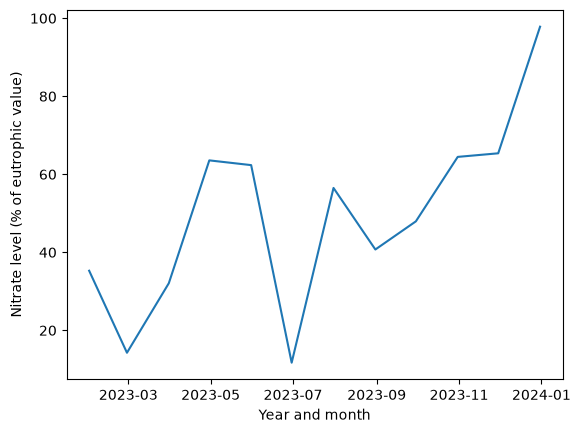

In [2]:
numdates = 12
np.random.seed(0)
time_series = 100 * (np.random.normal(size = numdates) / 5 + np.arange(numdates) / 16)
datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='M')
ax = sns.lineplot(x = datearray, y = time_series)
ax.set_xlabel("Year and month")
ax.set_ylabel("Nitrate level (% of eutrophic value)")

/var/folders/4p/8fvyx_j95j94r0vfr0rmb1s80000gn/T/ipykernel_43107/1726504607.py:3: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='M')


Text(0, 0.5, 'Phosphate level (% of eutrophic value)')

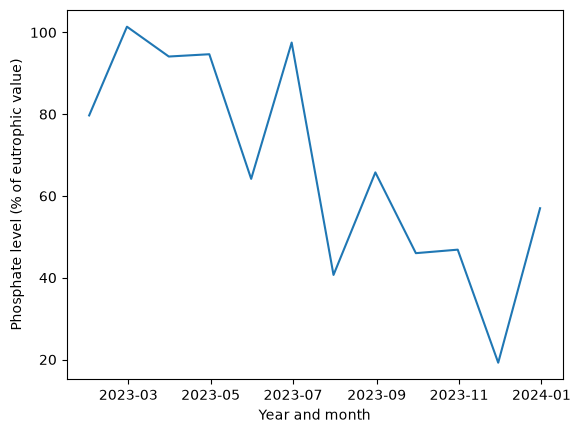

In [3]:
np.random.seed(1)
time_series_2 =  100 * (1 - (np.random.normal(size = numdates) / 8 + np.arange(numdates) / 16))
datearray = pd.date_range(start='2023/01/01', end='2024/01/01', freq='M')
ax = sns.lineplot(x = datearray, y = time_series_2)
ax.set_xlabel("Year and month")
ax.set_ylabel("Phosphate level (% of eutrophic value)")

<Axes: >

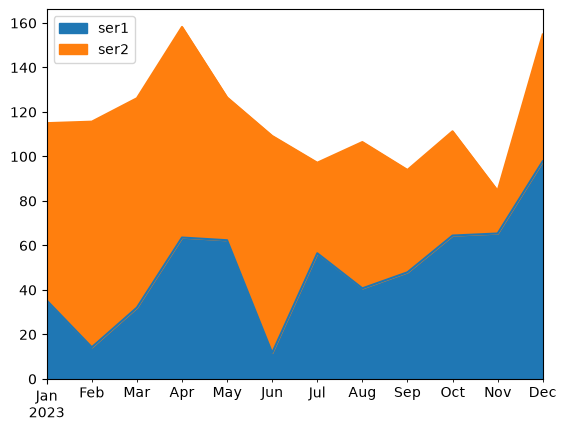

In [4]:
df = pd.DataFrame({'ser1': time_series, 'ser2': time_series_2}, index = datearray)
df.plot.area()

The area plot puts both chemicals on one graph, but it stacks phosphate on top of nitrate, so the top edge shows the two added together. That total doesn't mean anything here, and it makes the phosphate level hard to read because its area doesn't start at zero. The two separate line graphs show each chemical's own level clearly (nitrate goes up over the year and phosphate goes down), but the reader has to look back and forth between two graphs to compare them. I would put both as lines on one graph with the same y-axis, label each line directly instead of using the "ser1" and "ser2" legend, add a title and axis labels, and draw a dashed line at 100% to show the eutrophic level.

# 3. Working on your chosen project datasets this semester

This week, you will do the same types of exercises as last week, but you should use your chosen datasets that someone in your class found last semester. (They likely will not be the particular datasets that you found yourself.)

### Here are some types of analysis you can do:

- Find correlations between pairs of variables.

- Draw scatterplots, especially when the correlation is large.

- Draw pairplots.

- Draw line graphs and/or area graphs when there is date or time data together with numerical data.

### Conclusions:

- Explain what conclusions you would draw from this analysis: are the data what you expect?  Are the data likely to be usable?  If the data are not useable, find some new data!

- Do you see any outliers?  (Data points that are far from the rest of the data).

- Are any data items highly correlated with each other, suggesting that they are redundant?

- For the line plots, do you see a trend or pattern over time?  Does this suggest that the data are changing over time (drifting) in such a way as to invalidate comparisons?

- Can you think of any confounding variables?  (Third variables that could explain any correlations between other variables.  These third variables may or may not be reported in the dataset.)

**Dataset:** Diabetes 130-US Hospitals (1999–2008), UCI Machine Learning Repository
https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008

**File used:** diabetic_data.csv, loaded with `ucimlrepo` so the notebook runs on any machine. If that fails, it falls back to the local CSV.

Same cleaning steps as Weeks 2 and 4. The main outcome is `readmitted` (NO, >30, <30). I used the same types of plots and statistics as the Week 5 lesson: scatter plot, pair plot, correlations, waterfall plot, line plot, area plot, and ratios and percentages.

In [5]:
%pip install ucimlrepo

/Users/justinbosco/python-envs/omds/bin/python: No module named pip
Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from ucimlrepo import fetch_ucirepo
    df = fetch_ucirepo(id=296).data.original
except Exception:
    df = pd.read_csv('diabetic_data.csv')
rows_start = len(df)

id_cols = ['admission_type_id', 'discharge_disposition_id', 'admission_source_id']
df[id_cols] = df[id_cols].astype(str)
df = df.replace('?', np.nan)
df = df.drop(columns=['weight', 'payer_code', 'medical_specialty'])
df['race'] = df['race'].fillna('Unknown')
df = df.dropna(subset=['diag_1', 'diag_2', 'diag_3'])
rows_after_diag = len(df)
df['max_glu_serum'] = df['max_glu_serum'].fillna('Not tested')
df['A1Cresult'] = df['A1Cresult'].fillna('Not tested')
df = df[df['gender'] != 'Unknown/Invalid']
rows_after_gender = len(df)
df = df[~df['discharge_disposition_id'].isin(['11', '19', '20', '21'])]
print("Rows before cleaning:", rows_start)
print("Rows after cleaning:", len(df))

/Users/justinbosco/python-envs/omds/lib/python3.14/site-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


Rows before cleaning: 101766
Rows after cleaning: 98591


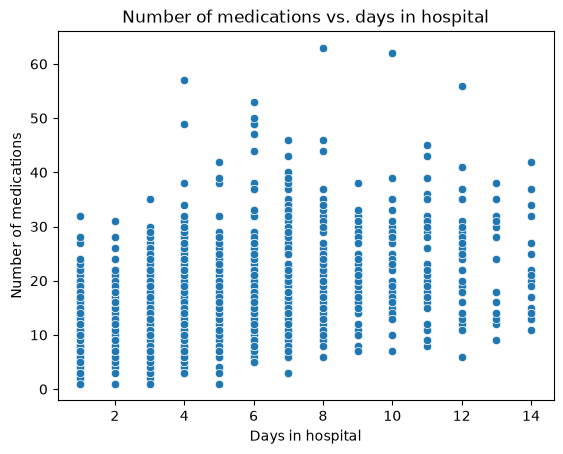

In [7]:
sample = df.sample(2000, random_state=0)

ax = sns.scatterplot(x = sample['time_in_hospital'], y = sample['num_medications'])
ax.set(title='Number of medications vs. days in hospital', xlabel='Days in hospital', ylabel='Number of medications')
plt.show()

Patients who stay longer tend to get more medications, but the dots are spread out a lot at every length of stay. I used a random sample of 2,000 visits so the dots don't all blend together.

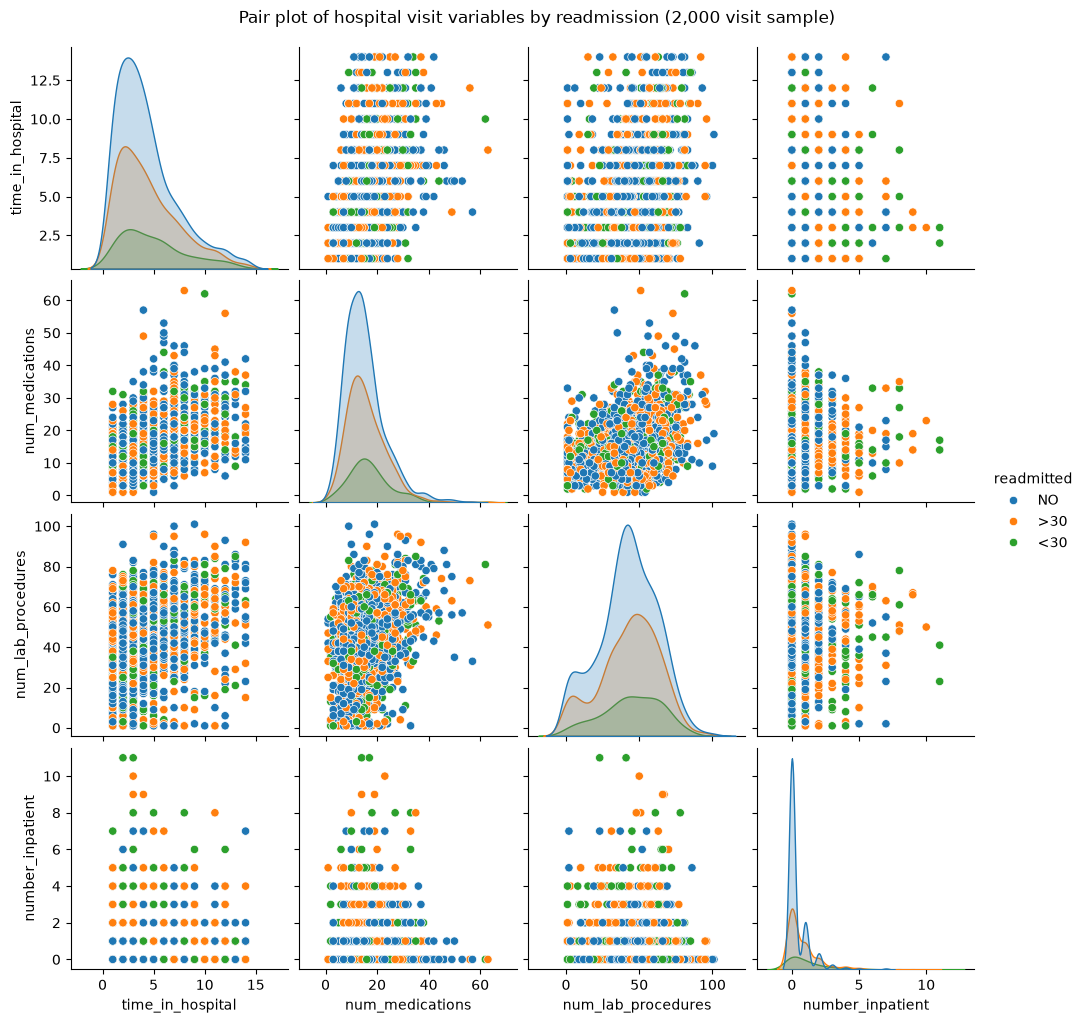

In [8]:
pair_cols = ['time_in_hospital', 'num_medications', 'num_lab_procedures', 'number_inpatient', 'readmitted']
g = sns.pairplot(sample[pair_cols], hue='readmitted', hue_order=['NO', '>30', '<30'])
g.figure.suptitle('Pair plot of hospital visit variables by readmission (2,000 visit sample)', y=1.02)
plt.show()

The three readmission groups overlap in every scatter plot, so none of these variables separates readmitted patients on its own. The clearest difference is in number_inpatient, where the <30 group has more patients with several prior inpatient visits.

In [9]:
df['readmitted_30'] = (df['readmitted'] == '<30').astype(int)
num_cols = ['time_in_hospital', 'num_lab_procedures', 'num_procedures', 'num_medications',
            'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'readmitted_30']
print("Correlations:")
df[num_cols].corr().round(2)

Correlations:


,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses,readmitted_30
time_in_hospital,1.00,0.32,0.19,0.46,-0.01,-0.01,0.07,0.21,0.04
num_lab_procedures,0.32,1.00,0.05,0.27,-0.01,-0.00,0.04,0.15,0.02
num_procedures,0.19,0.05,1.00,0.38,-0.03,-0.04,-0.07,0.06,-0.01
num_medications,0.46,0.27,0.38,1.00,0.04,0.01,0.06,0.24,0.04
number_outpatient,-0.01,-0.01,-0.03,0.04,1.00,0.09,0.11,0.09,0.02
number_emergency,-0.01,-0.00,-0.04,0.01,0.09,1.00,0.27,0.06,0.06
number_inpatient,0.07,0.04,-0.07,0.06,0.11,0.27,1.00,0.10,0.17
number_diagnoses,0.21,0.15,0.06,0.24,0.09,0.06,0.10,1.00,0.05
readmitted_30,0.04,0.02,-0.01,0.04,0.02,0.06,0.17,0.05,1.00


I added a `readmitted_30` column (1 if readmitted in under 30 days) so readmission could be included in the correlations. The strongest pair is time_in_hospital and num_medications (0.46), followed by num_procedures and num_medications (0.38) and time_in_hospital and num_lab_procedures (0.32). For 30-day readmission, number_inpatient has the highest correlation (0.17), and everything else is 0.06 or lower.

In [10]:
import plotly.graph_objects as go

changes = [rows_start, rows_after_diag - rows_start, rows_after_gender - rows_after_diag, len(df) - rows_after_gender]
fig = go.Figure(go.Waterfall(
    orientation='v',
    measure=['absolute', 'relative', 'relative', 'relative', 'total'],
    x=['Original data', 'Missing diagnosis', 'Unknown gender', 'Expired patients', 'Cleaned data'],
    textposition='outside',
    text=[str(c) for c in changes] + [str(len(df))],
    y=changes + [0],
    connector=dict(line=dict(color='rgb(63, 63, 63)'))
))

fig.update_layout(
    title='Rows removed at each cleaning step',
    xaxis_title='Cleaning step',
    yaxis_title='Number of rows',
    showlegend=False
)
fig.update_yaxes(range=[95000, 103000])
fig.show()

print("Rows removed for missing diagnosis:", rows_start - rows_after_diag)
print("Rows removed for unknown gender:", rows_after_diag - rows_after_gender)
print("Rows removed for expired patients:", rows_after_gender - len(df))
print("Percent of rows kept:", round(len(df) / rows_start * 100, 1))

Rows removed for missing diagnosis: 1522
Rows removed for unknown gender: 3
Rows removed for expired patients: 1650
Percent of rows kept: 96.9


The waterfall plot shows how the cleaning steps changed the data. It started with 101,766 rows. 1,522 were removed for a missing diagnosis, 3 for an unknown gender, and 1,650 for expired patients, which leaves 98,591 rows. That keeps 96.9% of the data.

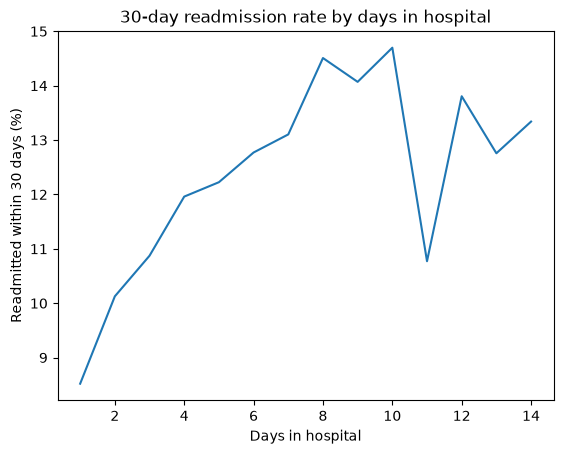

time_in_hospital
1      8.5
2     10.1
3     10.9
4     12.0
5     12.2
6     12.8
7     13.1
8     14.5
9     14.1
10    14.7
11    10.8
12    13.8
13    12.8
14    13.3
Name: readmitted_30, dtype: float64


In [11]:
rate_by_days = df.groupby('time_in_hospital')['readmitted_30'].mean() * 100

ax = sns.lineplot(x = rate_by_days.index, y = rate_by_days.values)
ax.set(title='30-day readmission rate by days in hospital', xlabel='Days in hospital', ylabel='Readmitted within 30 days (%)')
plt.show()
print(rate_by_days.round(1))

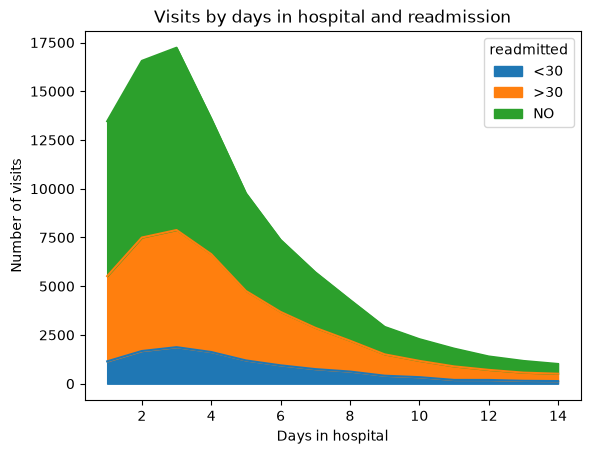

readmitted         <30   >30    NO
time_in_hospital                  
1                 1147  4372  7943
2                 1677  5821  9062
3                 1874  6009  9352
4                 1626  5021  6948
5                 1194  3565  5008
6                  942  2741  3693
7                  749  2120  2847
8                  624  1583  2094
9                  410  1096  1408
10                 336   836  1114
11                 194   695   912
12                 193   517   688
13                 149   419   600
14                 135   378   499


In [12]:
outcome_counts = pd.crosstab(df['time_in_hospital'], df['readmitted'])[['<30', '>30', 'NO']]

ax = outcome_counts.plot.area()
ax.set(title='Visits by days in hospital and readmission', xlabel='Days in hospital', ylabel='Number of visits')
plt.show()
print(outcome_counts)

The dataset has no admission dates, so I used days in hospital as the time variable. In the line plot, the 30-day readmission rate goes from 8.5% for 1-day stays up to 14.7% for 10-day stays, then levels off around 13% to 14%. The area plot shows that most visits are short stays, and the number of visits drops off quickly after about 4 days. The <30 layer is a small slice at every length of stay.

In [13]:
inpatient_pct = pd.crosstab(df['number_inpatient'].clip(upper=4), df['readmitted'], normalize='index') * 100
print("Readmission percentages by prior inpatient visits (4 = 4 or more):")
print(inpatient_pct.round(1))
print()
print("Ratio of <30 rate for 4+ prior visits vs. 0 prior visits:", round(inpatient_pct.loc[4, '<30'] / inpatient_pct.loc[0, '<30'], 1))

Readmission percentages by prior inpatient visits (4 = 4 or more):
readmitted         <30   >30    NO
number_inpatient                  
0                  8.6  30.7  60.7
1                 13.2  42.6  44.2
2                 17.8  48.8  33.4
3                 20.9  50.7  28.4
4                 31.2  49.4  19.4

Ratio of <30 rate for 4+ prior visits vs. 0 prior visits: 3.6


Prior inpatient visits make a big difference. Patients with no prior inpatient visits were readmitted within 30 days 8.6% of the time, compared with 31.2% for patients with 4 or more, which is about 3.6 times higher.

In [14]:
visit_cols = ['number_outpatient', 'number_emergency', 'number_inpatient']
print("Median:")
print(df[visit_cols].median())
print()
print("Max:")
print(df[visit_cols].max())

Median:
number_outpatient    0.0
number_emergency     0.0
number_inpatient     0.0
dtype: float64

Max:
number_outpatient    42
number_emergency     76
number_inpatient     21
dtype: int64


The median is 0 for all three prior visit counts, but the max is 42 outpatient, 76 emergency, and 21 inpatient visits. These look like real frequent users of the hospital rather than data errors, so I would keep them.

In [15]:
print("Visits:", len(df))
print("Unique patients:", df['patient_nbr'].nunique())
print("Repeat visits:", len(df) - df['patient_nbr'].nunique())

df['age_70_plus'] = df['age'].isin(['[70-80)', '[80-90)', '[90-100)'])
print()
print("Patients aged 70+ by readmission (%):")
print((df.groupby('readmitted')['age_70_plus'].mean() * 100).round(1))

Visits: 98591
Unique patients: 69333
Repeat visits: 29258

Patients aged 70+ by readmission (%):
readmitted
<30    48.2
>30    46.7
NO     43.7
Name: age_70_plus, dtype: float64


### Conclusions
- **Are the data what I expected, and are they usable?** Yes. After cleaning there are 98,591 visits (96.9% of the original data), and the relationships make sense: longer stays come with more medications, and more prior inpatient visits come with more readmissions. The numeric columns are only weakly correlated with 30-day readmission (highest 0.17), so a model will also need the categorical columns like diagnoses and medications.
- **Outliers:** Yes, in the prior visit counts. A few patients had up to 76 emergency visits, 42 outpatient visits, or 21 inpatient visits in the year before, compared with a median of 0.
- **Redundant variables:** No. The highest correlation between two variables is 0.46 (time_in_hospital and num_medications), which is not high enough for one to replace the other.
- **Trend over time:** The data cover 1999 to 2008, but there is no admission date column, so I can't check whether things drifted over those years. That is a limitation, because hospital practices likely changed over 10 years. By days in hospital, the 30-day readmission rate rises from 8.5% to 14.7% and then levels off.
- **Confounding variables:** How sick the patient is (not directly in the data) could explain both longer stays and more medications, and also more readmissions. Age is another one: 48.2% of <30 readmissions were patients aged 70+, compared with 43.7% of the NO group. Repeat patients also matter: there are only 69,333 unique patients for 98,591 visits, so 29,258 visits are repeats, and patients who keep coming back drive up both number_inpatient and readmission.

# 4. Storytelling With Data plot

Reproduce any graph of your choice in p. 86-98 of the Storytelling With Data book as best you can.  (The second half of chapter three).  You do not have to get the exact data values right, just the overall look and feel.

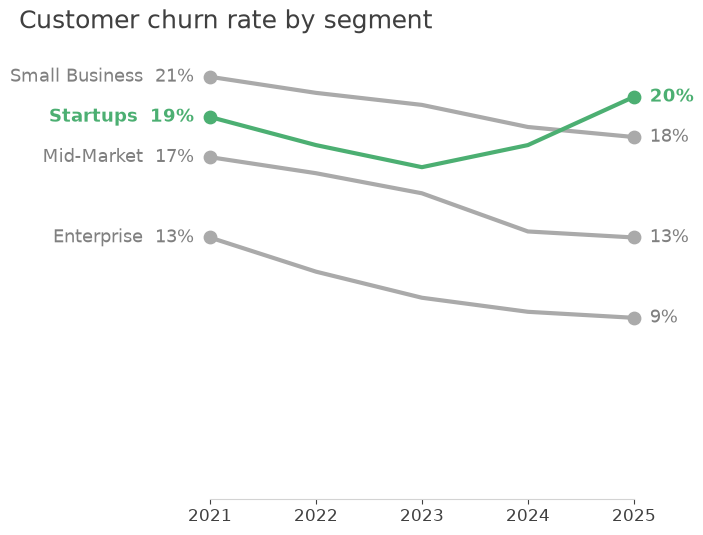

In [16]:
import matplotlib.pyplot as plt

years = [2021, 2022, 2023, 2024, 2025]
churn = {
    'Small Business': [21, 20.2, 19.6, 18.5, 18],
    'Startups': [19, 17.6, 16.5, 17.6, 20],
    'Mid-Market': [17, 16.2, 15.2, 13.3, 13],
    'Enterprise': [13, 11.3, 10, 9.3, 9],
}
gray = '#aaaaaa'
green = '#4caf72'

fig, ax = plt.subplots(figsize=(8, 6))
for segment, rates in churn.items():
    color = green if segment == 'Startups' else gray
    weight = 'bold' if segment == 'Startups' else 'normal'
    text_color = green if segment == 'Startups' else 'gray'
    ax.plot(years, rates, color=color, linewidth=3, zorder=3 if segment == 'Startups' else 2)
    ax.scatter([years[0], years[-1]], [rates[0], rates[-1]], color=color, s=80, zorder=4, clip_on=False)
    ax.text(years[0] - 0.15, rates[0], f'{segment}  {rates[0]:.0f}%', ha='right', va='center',
            fontsize=13, color=text_color, fontweight=weight)
    ax.text(years[-1] + 0.15, rates[-1], f'{rates[-1]:.0f}%', ha='left', va='center',
            fontsize=13, color=text_color, fontweight=weight)

ax.set_title('Customer churn rate by segment', loc='left', fontsize=18, color='#404040', x=-0.45)
ax.set_xticks(years)
ax.set_ylim(0, 23)
ax.set_xlim(2021, 2025)
ax.set_yticks([])
ax.spines[['top', 'right', 'left']].set_visible(False)
ax.spines['bottom'].set_color('lightgray')
ax.tick_params(axis='x', colors='#404040', labelsize=12)
fig.subplots_adjust(left=0.35, right=0.88)
plt.show()